*Previous notebook: adaptive optimizers: AdaGrad, Adadelta, RMSProp, Adam, Adamax, AMSGrad and Nadam. — This notebook: the dataset setup, why we normalise, weight initialisation, the baseline network and the bias/variance diagnosis.*

# Improving Neural Network Learning

Training a neural network involves more than just running gradient descent. Several techniques can dramatically affect how fast the network learns, how well it generalises to unseen data, and whether it gets stuck or diverges.

This notebook explores the most important ones using a **synthetic regression dataset** built from a combination of trigonometric and logarithmic functions with added Gaussian noise.

## 1. Synthetic Dataset

Import the required libraries:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Generate 1000 evenly-spaced points over $[0, 4\pi]$ and compute the target function:

$$y_{\text{true}}(x) = \sin(x) + 0.5\cos(2x) + 0.3\ln(x+1)$$

Then add Gaussian noise $\varepsilon \sim \mathcal{N}(0,\, 0.2^2)$ to simulate real-world measurements:

$$y_{\text{noisy}}(x) = y_{\text{true}}(x) + \varepsilon$$

In [2]:
np.random.seed(42)

x       = np.linspace(0, 4 * np.pi, 1000)
y_true  = np.sin(x) + 0.5 * np.cos(2 * x) + 0.3 * np.log(x + 1)
noise   = np.random.normal(0, 0.2, size=x.shape)
y_noisy = y_true + noise

df = pd.DataFrame({'x': x, 'y_true': y_true, 'y_noisy': y_noisy})
df.head()

,x,y_true,y_noisy
0,0.000000,0.500000,0.599343
1,0.012579,0.516171,0.488518
2,0.025158,0.531976,0.661514
3,0.037737,0.547417,0.852023
4,0.050316,0.562492,0.515662


Visualise the clean target function and the noisy observations:

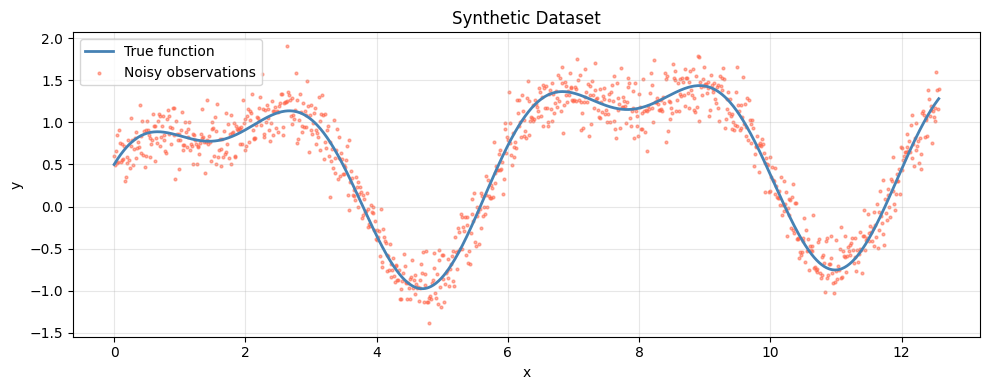

In [3]:
plt.figure(figsize=(10, 4))
plt.plot(df['x'], df['y_true'],  color='steelblue', linewidth=2, label='True function')
plt.scatter(df['x'], df['y_noisy'], color='tomato', s=4, alpha=0.5, label='Noisy observations')
plt.xlabel('x'); plt.ylabel('y')
plt.title('Synthetic Dataset')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

## 2. Train / Validation / Test Split

In [4]:
from sklearn.model_selection import train_test_split

X = df[['x']].values
y = df['y_noisy'].values.reshape(-1, 1)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val,   X_test,  y_val,  y_test  = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

print(f'Train: {X_train.shape[0]}  |  Val: {X_val.shape[0]}  |  Test: {X_test.shape[0]}')

Train: 700  |  Val: 150  |  Test: 150


## 3. Input Normalisation

The input $x$ spans $[0,\, 4\pi] \approx [0,\, 12.6]$. Feeding raw values of this magnitude into a network with small random weights produces very large pre-activations, which saturate sigmoid/tanh neurons and slow down learning.

**Standard score normalisation** rescales each feature to have zero mean and unit variance:

$$x_{\text{norm}} = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}$$

The statistics ($\mu$, $\sigma$) are computed **on the training set only** and then applied to validation and test sets — this prevents information from leaking into the model.

In [5]:
# Use the training set statistics to normalize all sets
mu    = X_train.mean()
sigma = X_train.std()

X_train_n = (X_train - mu) / sigma
X_val_n   = (X_val   - mu) / sigma
X_test_n  = (X_test  - mu) / sigma

print(f'Train mean: {X_train_n.mean():.4f}  std: {X_train_n.std():.4f}')

Train mean: -0.0000  std: 1.0000


### Why normalize?

If we don't normalize the inputs our cost function will be deep and its shape will be inconsistent (elongated) then optimizing it will take a long time.
But if we normalize it the opposite will occur. The shape of the cost function will be consistent (look more symmetric like circle in 2D example) and we can use a larger learning rate alpha - the optimization will be faster.

So, if you normalize your inputs this will **speed up the training** process a lot.

## 4. Baseline Network

A fully-connected network with two hidden layers and **ReLU** activations. The output layer is linear (no activation) since this is a regression task.

Architecture: $1 \to 32 \to 32 \to 1$

In [6]:
def relu(z):      
    return np.maximum(0, z)

def relu_deriv(z):  
    return (z > 0).astype(float)

**He initialisation** sets the initial weights by drawing from $\mathcal{N}\!\left(0,\, \sqrt{2/n_{\text{in}}}\right)$, which keeps the variance of activations stable across layers when using ReLU.

In [7]:
def init_params(layer_sizes, seed=0):
    np.random.seed(seed)
    params = {}
    for i in range(1, len(layer_sizes)):
        fan_in = layer_sizes[i - 1]
        params[f'W{i}'] = np.random.randn(fan_in, layer_sizes[i]) * np.sqrt(2 / fan_in)
        params[f'b{i}'] = np.zeros((1, layer_sizes[i]))
    return params

layer_sizes = [1, 32, 32, 1]
params = init_params(layer_sizes)
print({k: v.shape for k, v in params.items()})

{'W1': (1, 32), 'b1': (1, 32), 'W2': (32, 32), 'b2': (1, 32), 'W3': (32, 1), 'b3': (1, 1)}


#### Weight Initialization for Deep Networks

Proper weight initialization is one of the key techniques used to mitigate the vanishing and exploding gradients problem in deep neural networks. The core idea is that the way we choose the initial values of the weights strongly affects how signals and gradients propagate through many layers.

To understand this, consider a single neuron where the linear combination is given by \( Z = w_1 x_1 + w_2 x_2 + \dots + w_n x_n \). If the number of input features \( n \) is large, then using weights that are too large can easily cause the output to grow uncontrollably as it propagates through layers, leading to exploding activations. For this reason, we want the variance of the weights to scale inversely with the number of input connections, typically around \( 1/n_x \), so that the signal remains stable as it moves forward through the network.

This idea leads to different initialization strategies. For activations like tanh, a common choice is Xavier initialization, where weights are sampled as:

```python
np.random.randn(shape) * np.sqrt(1 / n[l-1])
```

A more general version proposed by Bengio and collaborators uses:

```python
np.random.randn(shape) * np.sqrt(2 / (n[l-1] + n[l]))
```

For ReLU activations, a particularly effective variant is He initialization:

```python
np.random.randn(shape) * np.sqrt(2 / n[l-1])
```

In practice, the constant in the numerator (such as 1 or 2) can also be treated as a hyperparameter, but these standard forms already provide strong performance and are usually good starting points. 

The vanishing and exploding gradients problem itself arises because, in a very deep network, repeated multiplication by weight matrices can cause activations and gradients to either shrink or grow exponentially with the number of layers.

**Forward pass** — propagate the input through each layer:

$$z^{(l)} = a^{(l-1)} \cdot W^{(l)} + b^{(l)}, \qquad a^{(l)} = \text{ReLU}(z^{(l)})$$

The output layer has no activation: $\hat{y} = z^{(L)}$.

In [8]:
def forward(X, params):
    cache = {'a0': X}
    a = X
    n_layers = len(params) // 2

    for i in range(1, n_layers):        # hidden layers — ReLU
        z = a @ params[f'W{i}'] + params[f'b{i}']
        a = relu(z)
        cache[f'z{i}'] = z
        cache[f'a{i}'] = a

    i = n_layers                        # output layer — linear
    z = a @ params[f'W{i}'] + params[f'b{i}']
    cache[f'z{i}'] = z
    cache[f'a{i}'] = z
    
    return z, cache

**Backward pass** — compute gradients via the chain rule.

Output layer (linear activation):
$$\delta^{(L)} = -(y - \hat{y})$$

Hidden layer $l$ (ReLU):
$$\delta^{(l)} = \left(\delta^{(l+1)} \cdot W^{(l+1)T}\right) \odot \text{ReLU}'(z^{(l)})$$

Weight gradients:
$$\frac{\partial J}{\partial W^{(l)}} = a^{(l-1)T} \cdot \delta^{(l)}, \qquad \frac{\partial J}{\partial b^{(l)}} = \sum \delta^{(l)}$$

In [9]:
def backward(y, y_hat, params, cache):
    m = y.shape[0]
    grads = {}
    n_layers = len(params) // 2
    delta = -(y - y_hat) / m

    for i in range(n_layers, 0, -1):
        grads[f'dW{i}'] = cache[f'a{i-1}'].T @ delta
        grads[f'db{i}'] = delta.sum(axis=0, keepdims=True)

        if i > 1:
            delta = delta @ params[f'W{i}'].T * relu_deriv(cache[f'z{i-1}'])
            
    return grads

Update each weight matrix with the standard gradient descent rule: $W \leftarrow W - \alpha \cdot \nabla_W J$

In [10]:
def update_params(params, grads, lr):
    for key in params:
        params[key] -= lr * grads['d' + key]
        
    return params

**Mean Squared Error** loss:

$$J = \frac{1}{m} \sum_{i=1}^{m} (y_i - \hat{y}_i)^2$$

In [11]:
def mse(y, y_hat):
    return np.mean((y - y_hat) ** 2)

## 5. Training the Baseline

Train for a fixed number of epochs using full-batch gradient descent. Both training and validation loss are recorded at every epoch to detect overfitting.

In [12]:
import time

def train(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    start = time.time()
    for _ in range(epochs):
        y_hat, cache = forward(X_tr, params)
        grads        = backward(y_tr, y_hat, params, cache)
        params       = update_params(params, grads, lr)
        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _   = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

params_base, tl_base, vl_base, t_base = train(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1], lr=1e-2, epochs=2000
)

Final train MSE: 0.2857  |  val MSE: 0.2486  |  time: 2.48s


Plot training and validation loss curves to check for overfitting:

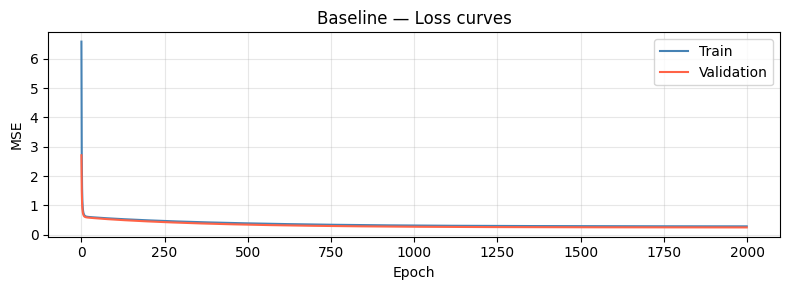

In [13]:
def plot_loss(train_loss, val_loss, title='Loss curves'):
    plt.figure(figsize=(8, 3))
    plt.plot(train_loss, label='Train',      color='steelblue')
    plt.plot(val_loss,   label='Validation', color='tomato')
    plt.xlabel('Epoch'); plt.ylabel('MSE')
    plt.title(title); plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

plot_loss(tl_base, vl_base, title='Baseline — Loss curves')

It's important to print train/validation loss for the bias/variance problem:

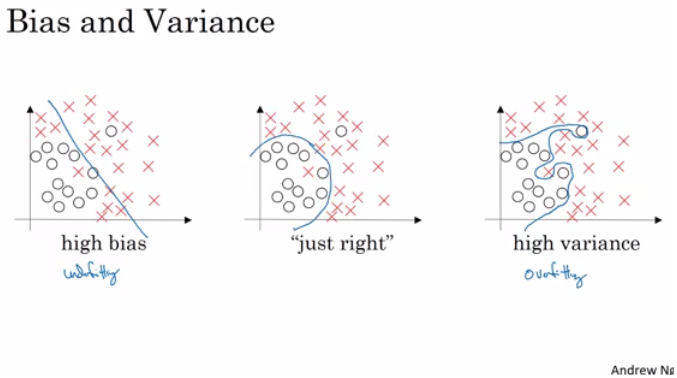

<br>

High variance (overfitting) for example: Training error: 1%, Val error: 11% <br>
high Bias (underfitting) for example: Training error: 15%, Val error: 14% <br>
high Bias (underfitting) && High variance (overfitting) for example: Training error: 15%, Test error: 30% <br>
Best: Training error: 0.5%, Test error: 1% <br>

If your algorithm has a high bias:
- Try to make your NN bigger (size of hidden units, number of layers)
- Try a different model that is suitable for your data.
- Try to run it longer.
- Different (advanced) optimization algorithms. <br>

If your algorithm has a high variance:
- More data.
- Try regularization.
- Try a different model that is suitable for your data. <br>

You should try the previous two points until you have a low bias and low variance.
In the older days before deep learning, there was a "Bias/variance tradeoff". But because now you have more options/tools for solving the bias and variance problem its really helpful to use deep learning.
Training a bigger neural network never hurts.